# BITS PILANI
## Work Integrated Learning Programmes Division

### M.Tech – Artificial Intelligence and Machine Learning
### Semester 1 – July 2026 Batch

# Machine Learning – Assignment 2

## Bank Marketing Term Deposit Prediction

---

### Student Details

- **Name:** CHANDAR KUMAR V.
- **Student ID:** 2026AK05314
- **Programme:** M.Tech Artificial Intelligence and Machine Learning
- **Semester:** 1

### Assignment Details

- **Subject:** Machine Learning
- **Assignment Number:** 2
- **Maximum Marks:** 15
- **Submission Date:** 08 November 2026
- **Dataset:** Bank Marketing Dataset
- **Dataset Source:** UCI Machine Learning Repository
- **Problem Type:** Binary Classification

---

## Introduction

In this assignment, I am using the Bank Marketing dataset to
implement and compare five different machine learning
classification algorithms.

The main objective is to predict whether a customer will
subscribe to a bank term deposit based on the available
customer and campaign-related information.

I will train the five classification models using the same
dataset and compare their performance using the evaluation
metrics specified in the assignment.

### Models Implemented

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbour (KNN)
4. Naive Bayes
5. Support Vector Machine (SVM)

### Evaluation Metrics

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

---

## 1. Importing Required Libraries

In this section, I am importing the Python libraries required
for loading the dataset, performing data analysis and building
the machine learning models.

The following libraries will be used:

- Pandas for reading and handling the dataset.
- NumPy for numerical calculations.
- Pathlib for handling file paths.

In [4]:
# Import the required libraries

import pandas as pd
import numpy as np

from pathlib import Path

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.4


## 2. Loading the Dataset

For this assignment, I have selected the Bank Marketing
dataset from the UCI Machine Learning Repository.

The dataset contains information about customers and bank
marketing campaigns. The target variable indicates whether
the customer subscribed to a term deposit or not.

I am loading the bank-full.csv file using Pandas.
The original file uses a semicolon as the separator.

In [5]:
# Load the Bank Marketing dataset

DATASET_PATH = Path("data/bank-full.csv")

df = pd.read_csv(DATASET_PATH, sep=";")

# Display the basic details of the dataset

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (45211, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Dataset Quality Assessment

Before building the machine learning models, I am checking
the dataset to understand its structure and quality.

The following checks are performed:

1. Dataset information and data types.
2. Missing values in each column.
3. Duplicate records.
4. Distribution of the target variable.
5. Percentage distribution of the target classes.

These checks will help me understand the dataset and decide
the preprocessing steps required before model training.

In [6]:
# Display the dataset information

print("Dataset Information:")
df.info()

# Check for missing values in each column

print("\nMissing values in each column:")
display(df.isnull().sum())

# Check the number of duplicate records

print("\nNumber of duplicate records:")
print(df.duplicated().sum())

# Check the distribution of the target variable

print("\nTarget variable distribution:")
display(df["y"].value_counts())

# Display the target distribution in percentage

print("\nTarget distribution in percentage:")
display(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB

Missing values in each column:


age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


Number of duplicate records:
0

Target variable distribution:


y
no     39922
yes     5289
Name: count, dtype: int64


Target distribution in percentage:


y
no     88.3
yes    11.7
Name: proportion, dtype: float64

### Observation

From the above dataset analysis, I observed the following:

1. The dataset contains 45,211 records and 17 columns, including 16 input features and one target variable.

2. The dataset contains 7 numerical columns and 10 categorical columns.

3. There are no missing values in any of the columns.

4. No duplicate records were found in the dataset.

5. The target variable has two classes: yes and no.

6. Around 88.3% of the customers did not subscribe to a term deposit, whereas only 11.7% subscribed.

The target classes are imbalanced. Therefore, I will consider
this while training the models and comparing their performance.


## 4. Exploratory Data Analysis

In this section, I am performing exploratory data analysis
to understand the distribution of different features in
the Bank Marketing dataset.

First, I will separate the numerical and categorical columns.
This will help me understand the different types of data
available for building the classification models.

In [7]:
# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()

categorical_columns = df.select_dtypes(exclude=["number"]).columns.tolist()

# Remove the target column from the categorical input features

categorical_features = [
    col for col in categorical_columns if col != "y"
]

print("Numerical features:")
print(numerical_columns)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_columns))
print("Number of categorical features:", len(categorical_features))


Numerical features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 7
Number of categorical features: 9


### Observation

From the feature identification, I found that the dataset
contains 7 numerical features and 9 categorical input features.

The numerical features include age, balance, day, duration,
campaign, pdays and previous.

The categorical features include job, marital, education,
default, housing, loan, contact, month and poutcome.

The target variable 'y' is kept separate from the input features.

### 4.1 Distribution of Numerical Features

In this section, I am checking the descriptive statistics
of the numerical columns.

This gives an idea about the average, minimum, maximum and
spread of the numerical values in the dataset.

In [8]:
# Display summary statistics for numerical features

display(df[numerical_columns].describe().round(2))

,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


### Observation

From the above statistical summary, I observed that the age
of customers ranges from 18 to 95 years, with an average
age of approximately 41 years.

The balance values vary considerably, with both negative
and positive values. The campaign feature shows that the
number of contacts also varies across customers.

I also observed that the pdays feature has a minimum value
of -1, which indicates that some customers were not
previously contacted.

The numerical features have different value ranges.
Therefore, scaling will be considered during preprocessing
for models that are sensitive to feature magnitudes.

### 4.2 Target Class Distribution

The target variable is 'y', which indicates whether a customer
subscribed to a term deposit.

I am plotting the number of customers in each target class
to understand the class distribution visually.

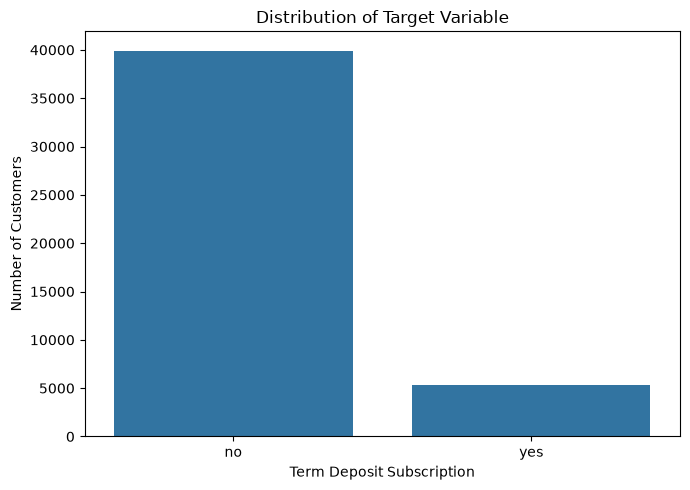

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the target class distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="y")

plt.title("Distribution of Target Variable")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Observation

From the above graph, I observed that the number of customers
who did not subscribe to a term deposit is much higher than
the number of customers who subscribed.

- The 'no' class contains 39,922 customers (88.3%).
- The 'yes' class contains 5,289 customers (11.7%).

This shows that the target variable is imbalanced.

Because of this imbalance, accuracy alone may not give a
complete picture of model performance. Therefore, I will
also consider precision, recall, F1 score, AUC and MCC
while comparing the models.

## 5. Data Preprocessing

### 5.1 Selection of Input Features and Target Variable

In this section, I am separating the input features and the
target variable before building the classification models.

The target variable is 'y', which indicates whether the customer
subscribed to a term deposit.

I have excluded the 'duration' column because it represents
the duration of the call, which is known only after contacting
the customer. Including this feature may affect the prediction
when the objective is to predict subscription before making
the call.

The remaining 15 input features will be used for model training.

In [10]:
# Separate the input features and target variable

X = df.drop(columns=["y", "duration"])
y = df["y"]

# Display the shape of input features and target variable

print("Input feature shape:", X.shape)
print("Target variable shape:", y.shape)

# Display the selected input features

print("\nSelected input features:")
print(X.columns.tolist())

# Display the target classes

print("\nTarget classes:")
print(y.unique())

Input feature shape: (45211, 15)
Target variable shape: (45211,)

Selected input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target classes:
<ArrowStringArray>
['no', 'yes']
Length: 2, dtype: str


### 5.2 Encoding Categorical Features and Scaling Numerical Features

The selected dataset contains both numerical and categorical
features. These features need to be converted into a suitable
format before applying machine learning algorithms.

I will use the following preprocessing methods:

1. One-Hot Encoding to convert categorical features into
   numerical values.
2. Standard Scaling to bring numerical features to a
   comparable scale.

I will use a preprocessing pipeline so that the same
transformations can be applied consistently during model
training and testing.

The preprocessing steps will be fitted using the training
data to avoid data leakage.

In [12]:
# Import preprocessing tools from Scikit-learn

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify numerical and categorical input features

numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

# Apply standard scaling to numerical features

numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Apply one-hot encoding to categorical features

categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing methods

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully!

Numerical features: 6
Categorical features: 9


### 5.3 Splitting the Dataset into Training and Testing Sets

Before training the classification models, I am splitting
the dataset into training and testing sets.

I am using an 80:20 split, where 80% of the records will be
used for training and the remaining 20% will be used for testing.

I am also using stratified sampling to maintain the same
proportion of both target classes in the training and
testing sets.

A fixed random state is used to obtain reproducible results.

In [14]:
# Import the train-test split function

from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of records in each set

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data shape: (36168, 15)
Testing data shape: (9043, 15)

Training target distribution:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64

Testing target distribution:
y
no     0.883
yes    0.117
Name: proportion, dtype: float64


## 6. Building and Evaluating Classification Models

In this section, I will implement five classification
algorithms using the training dataset.

The same training and testing datasets will be used for
all five models to ensure a fair comparison.

The preprocessing pipeline will be included with each
model so that numerical scaling and categorical encoding
are applied consistently.

I will evaluate each model using the six metrics specified
in the assignment:

1. Accuracy
2. AUC Score
3. Precision
4. Recall
5. F1 Score
6. Matthews Correlation Coefficient (MCC)

### 6.1 Logistic Regression

Logistic Regression is a supervised machine learning
algorithm used for classification problems.

In this assignment, I am using Logistic Regression to
predict whether a customer will subscribe to a term deposit.

The model uses the input features to estimate the probability
of a customer belonging to the 'yes' or 'no' class.

I will use the preprocessing pipeline along with Logistic
Regression and evaluate its performance using the six
metrics specified in the assignment.

In [15]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model with preprocessing

logistic_regression = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using training data

logistic_regression.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 6.1.1 Evaluation of Logistic Regression

After training the Logistic Regression model, I am evaluating
its performance using the test dataset.

The following six metrics are used:

1. Accuracy – Measures the overall percentage of correct predictions.
2. AUC Score – Measures how well the model separates the two classes.
3. Precision – Measures how many predicted positive cases are actually positive.
4. Recall – Measures how many actual positive cases are correctly identified.
5. F1 Score – Represents the balance between precision and recall.
6. MCC – Measures the overall quality of binary classification predictions.

In [17]:
# Import the required evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Predict the target values for test data

y_pred_lr = logistic_regression.predict(X_test)

# Calculate the probability of the positive class

y_prob_lr = logistic_regression.predict_proba(X_test)[:, 1]

# Calculate all six evaluation metrics

lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "AUC": roc_auc_score(y_test, y_prob_lr),
    "Precision": precision_score(y_test, y_pred_lr, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred_lr, pos_label="yes"),
    "F1 Score": f1_score(y_test, y_pred_lr, pos_label="yes"),
    "MCC": matthews_corrcoef(y_test, y_pred_lr)
}

# Display the evaluation results

print("Logistic Regression - Evaluation Metrics")

for metric, value in lr_metrics.items():
    print(f"{metric}: {value:.4f}")

Logistic Regression - Evaluation Metrics
Accuracy: 0.7548
AUC: 0.7722
Precision: 0.2662
Recall: 0.6238
F1 Score: 0.3732
MCC: 0.2853


### Observation

From the evaluation results, Logistic Regression achieved an
accuracy of 75.48% and an AUC score of 0.7722.

The recall is 0.6238, which indicates that the model identifies
a reasonable proportion of customers who subscribed to a
term deposit.

However, the precision is 0.2662, indicating that some
customers predicted as subscribers did not actually subscribe.

The F1 score is 0.3732 and the MCC score is 0.2853.
These results indicate that there is scope for improving
the classification performance.

### 6.2 Decision Tree Classifier

Decision Tree is a supervised machine learning algorithm
used for classification and regression problems.

It works by dividing the dataset into smaller groups based
on feature values. The model uses a series of decision rules
to predict the target class.

In this assignment, I am using a Decision Tree Classifier
to predict whether a customer will subscribe to a term deposit.

I will evaluate its performance using the same six metrics
used for Logistic Regression.

In [18]:
# Import Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model with preprocessing

decision_tree = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model using training data

decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


### 6.2.1 Evaluation of Decision Tree

After training the Decision Tree model, I am evaluating its
performance using the test dataset.

I will calculate the same six evaluation metrics used for
Logistic Regression so that the performance of both models
can be compared.

The metrics include Accuracy, AUC Score, Precision, Recall,
F1 Score and Matthews Correlation Coefficient (MCC).

In [19]:
# Predict the target values for test data

y_pred_dt = decision_tree.predict(X_test)

# Calculate the probability of the positive class

y_prob_dt = decision_tree.predict_proba(X_test)[:, 1]

# Calculate all six evaluation metrics

dt_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "AUC": roc_auc_score(y_test, y_prob_dt),
    "Precision": precision_score(y_test, y_pred_dt, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred_dt, pos_label="yes"),
    "F1 Score": f1_score(y_test, y_pred_dt, pos_label="yes"),
    "MCC": matthews_corrcoef(y_test, y_pred_dt)
}

# Display the evaluation results

print("Decision Tree - Evaluation Metrics")

for metric, value in dt_metrics.items():
    print(f"{metric}: {value:.4f}")

Decision Tree - Evaluation Metrics
Accuracy: 0.8401
AUC: 0.6036
Precision: 0.3083
Recall: 0.2949
F1 Score: 0.3014
MCC: 0.2113


### Observation

From the evaluation results, the Decision Tree model achieved
an accuracy of 84.01% and an AUC score of 0.6036.

The precision is 0.3083 and the recall is 0.2949. This indicates
that the model identifies only a limited proportion of customers
who actually subscribed to a term deposit.

The F1 score is 0.3014 and the MCC score is 0.2113.

Although the accuracy is higher than Logistic Regression,
the AUC, recall, F1 score and MCC are lower. Therefore,
accuracy alone is not sufficient to judge this model.

### 6.3 K-Nearest Neighbour Classifier

K-Nearest Neighbour (KNN) is a supervised machine learning
algorithm used for classification and regression problems.

It predicts the class of a new data point by finding the
nearest data points in the training dataset and selecting
the majority class among its neighbours.

In this assignment, I am using KNN to predict whether a
customer will subscribe to a term deposit.

Since KNN uses distances between data points, numerical
feature scaling is important for this algorithm.

In [20]:
# Import K-Nearest Neighbour Classifier

from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model with preprocessing

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ))
])

# Train the model using training data

knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


### 6.3.1 Evaluation of K-Nearest Neighbour

After training the KNN model, I am evaluating its performance
using the test dataset.

The model predictions will be compared with the actual target
values to calculate the six evaluation metrics.

The metrics include Accuracy, AUC Score, Precision, Recall,
F1 Score and Matthews Correlation Coefficient (MCC).

In [21]:
# Predict the target values for test data

y_pred_knn = knn_model.predict(X_test)

# Calculate the probability of the positive class

y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate all six evaluation metrics

knn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "AUC": roc_auc_score(y_test, y_prob_knn),
    "Precision": precision_score(y_test, y_pred_knn, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred_knn, pos_label="yes"),
    "F1 Score": f1_score(y_test, y_pred_knn, pos_label="yes"),
    "MCC": matthews_corrcoef(y_test, y_pred_knn)
}

# Display the evaluation results

print("KNN - Evaluation Metrics")

for metric, value in knn_metrics.items():
    print(f"{metric}: {value:.4f}")

KNN - Evaluation Metrics
Accuracy: 0.8874
AUC: 0.7027
Precision: 0.5529
Recall: 0.1975
F1 Score: 0.2911
MCC: 0.2833


### Observation

From the evaluation results, the KNN model achieved an
accuracy of 88.74% and an AUC score of 0.7027.

The precision is 0.5529, which indicates that the model
correctly identifies a reasonable proportion of customers
predicted as term deposit subscribers.

However, the recall is 0.1975, which shows that the model
identifies only a small proportion of actual subscribers.

The F1 score is 0.2911 and the MCC score is 0.2833.

Although KNN has the highest accuracy among the three models
evaluated so far, its low recall indicates that it misses
many actual subscribers.

### 6.4 Naive Bayes Classifier

Naive Bayes is a supervised machine learning algorithm
based on Bayes' theorem.

It calculates the probability of a class based on the
available input features. It assumes that the features
are conditionally independent of each other given the class.

In this assignment, I am using Gaussian Naive Bayes to
predict whether a customer will subscribe to a term deposit.

Gaussian Naive Bayes is suitable for numerical input
features, and the preprocessing pipeline converts the
categorical features into numerical representations.

In [22]:
# Import Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

# Create the Naive Bayes model with preprocessing

naive_bayes = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GaussianNB())
])

# Train the model using training data

naive_bayes.fit(X_train, y_train)

print("Gaussian Naive Bayes model trained successfully!")

Gaussian Naive Bayes model trained successfully!


### 6.4.1 Evaluation of Gaussian Naive Bayes

After training the Gaussian Naive Bayes model, I am evaluating
its performance using the test dataset.

I will compare the predicted values with the actual target
values and calculate the six evaluation metrics specified
in the assignment.

The metrics include Accuracy, AUC Score, Precision, Recall,
F1 Score and Matthews Correlation Coefficient (MCC).

In [23]:
# Predict the target values for test data

y_pred_nb = naive_bayes.predict(X_test)

# Calculate the probability of the positive class

y_prob_nb = naive_bayes.predict_proba(X_test)[:, 1]

# Calculate all six evaluation metrics

nb_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_nb),
    "AUC": roc_auc_score(y_test, y_prob_nb),
    "Precision": precision_score(y_test, y_pred_nb, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred_nb, pos_label="yes"),
    "F1 Score": f1_score(y_test, y_pred_nb, pos_label="yes"),
    "MCC": matthews_corrcoef(y_test, y_pred_nb)
}

# Display the evaluation results

print("Gaussian Naive Bayes - Evaluation Metrics")

for metric, value in nb_metrics.items():
    print(f"{metric}: {value:.4f}")

Gaussian Naive Bayes - Evaluation Metrics
Accuracy: 0.8452
AUC: 0.7514
Precision: 0.3708
Recall: 0.4641
F1 Score: 0.4123
MCC: 0.3271


### Observation

From the evaluation results, I observed that the Gaussian Naive Bayes model achieved an accuracy of 84.52% and an AUC score of 0.7514.

The model achieved a precision of 0.3708 and a recall of 0.4641. Its F1 score is 0.4123, which is higher than the Logistic Regression, Decision Tree and KNN models evaluated so far.

The MCC value of 0.3271 is also the highest among these four models. This indicates that Gaussian Naive Bayes provides a better balance between precision and recall compared with the other three models.

### 6.5 Support Vector Machine (SVM)

Support Vector Machine is a supervised learning algorithm used for classification. It tries to find an optimal decision boundary that separates the different classes.

For this assignment, I am using Linear Support Vector Machine (Linear SVM). It is suitable for high-dimensional data and is computationally more efficient for this dataset.

The preprocessing pipeline is used to scale numerical features and encode categorical features before training the model.

In [24]:
from sklearn.svm import LinearSVC

svm_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    ))
])

svm_model.fit(X_train, y_train)

print("Linear SVM model trained successfully!")

Linear SVM model trained successfully!


### 6.5.1 Evaluation of Support Vector Machine

After training the Linear SVM model, I evaluate its performance using the test dataset.

I use the same six evaluation metrics used for the previous models: Accuracy, AUC, Precision, Recall, F1 Score and MCC.

In [25]:
# Predict the target values for test data

y_pred_svm = svm_model.predict(X_test)

# Get decision scores for calculating AUC

y_score_svm = svm_model.decision_function(X_test)

# Calculate all six evaluation metrics

svm_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "AUC": roc_auc_score(y_test, y_score_svm),
    "Precision": precision_score(y_test, y_pred_svm, pos_label="yes"),
    "Recall": recall_score(y_test, y_pred_svm, pos_label="yes"),
    "F1 Score": f1_score(y_test, y_pred_svm, pos_label="yes"),
    "MCC": matthews_corrcoef(y_test, y_pred_svm)
}

# Display the evaluation results

print("Linear SVM - Evaluation Metrics")

for metric, value in svm_metrics.items():
    print(f"{metric}: {value:.4f}")

Linear SVM - Evaluation Metrics
Accuracy: 0.7578
AUC: 0.7718
Precision: 0.2684
Recall: 0.6200
F1 Score: 0.3746
MCC: 0.2867


### Observation

From the evaluation results, I observed that the Linear SVM model achieved an accuracy of 75.78% and an AUC score of 0.7718.

The model achieved a precision of 0.2684 and a recall of 0.6200. Its F1 score is 0.3746 and MCC is 0.2867.

The recall is reasonably high, which means the model identifies a good proportion of customers who subscribed to a term deposit. However, its precision is relatively low, indicating that some customers predicted as subscribers did not actually subscribe.

## 7. Comparison of All Classification Models

In this section, I compare the performance of all five classification models using the six evaluation metrics. This helps me understand how each model performs on the same test dataset.

In [26]:
# Combine the evaluation results of all five models

comparison_df = pd.DataFrame({
    "Logistic Regression": lr_metrics,
    "Decision Tree": dt_metrics,
    "KNN": knn_metrics,
    "Gaussian Naive Bayes": nb_metrics,
    "Linear SVM": svm_metrics
})

# Display the comparison table

display(comparison_df.round(4))

,Logistic Regression,Decision Tree,KNN,Gaussian Naive Bayes,Linear SVM
Accuracy,0.7548,0.8401,0.8874,0.8452,0.7578
AUC,0.7722,0.6036,0.7027,0.7514,0.7718
Precision,0.2662,0.3083,0.5529,0.3708,0.2684
Recall,0.6238,0.2949,0.1975,0.4641,0.6200
F1 Score,0.3732,0.3014,0.2911,0.4123,0.3746
MCC,0.2853,0.2113,0.2833,0.3271,0.2867


### 7.1 Overall Comparison and Observations

From the comparison table, I observed that each classification model performs differently across the evaluation metrics.

- KNN achieved the highest accuracy of 88.74% and precision of 0.5529.
- Logistic Regression achieved the highest AUC of 0.7722 and recall of 0.6238.
- Gaussian Naive Bayes achieved the highest F1 score of 0.4123 and MCC of 0.3271.
- Decision Tree achieved an accuracy of 84.01%, but its recall and F1 score were comparatively low.
- Linear SVM showed performance similar to Logistic Regression in terms of AUC and recall.

Since the dataset is imbalanced, accuracy alone is not sufficient to select the best model. F1 score and MCC provide additional information about the model's overall classification performance.

Based on the results, Gaussian Naive Bayes performed best in terms of F1 score and MCC. Therefore, I consider Gaussian Naive Bayes the best overall model among the five models evaluated in this experiment.

## 8. Saving the Trained Models

After evaluating all five classification models, I save the trained models using Joblib.

Each saved pipeline contains the preprocessing steps and the trained classifier. These saved models will be used by the Streamlit application for prediction and evaluation without training the models again.

In [30]:
import joblib
from pathlib import Path

# Create the model directory

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

# Collect all five trained models

models = {
    "logistic_regression": logistic_regression,
    "decision_tree": decision_tree,
    "knn": knn_model,
    "gaussian_naive_bayes": naive_bayes,
    "linear_svm": svm_model
}

# Save each trained model

for model_name, model in models.items():
    model_path = MODEL_DIR / f"{model_name}.joblib"
    joblib.dump(model, model_path)
    print(f"Saved successfully: {model_path}")

print("\nAll five models saved successfully!")

Saved successfully: model\logistic_regression.joblib
Saved successfully: model\decision_tree.joblib
Saved successfully: model\knn.joblib
Saved successfully: model\gaussian_naive_bayes.joblib
Saved successfully: model\linear_svm.joblib

All five models saved successfully!


## 9. Preparing Test Data for the Streamlit Application

I prepare a separate test dataset containing the input features and actual target values.

This CSV file will be uploaded through the Streamlit application to evaluate the saved models. The application will load the trained models without performing training again.

In [32]:
# Combine test features and actual target values

test_data = X_test.copy()
test_data["y"] = y_test.values

# Save the test dataset in the project directory

test_data.to_csv("test_data.csv", index=False)

print("Test dataset saved successfully!")
print("Test dataset shape:", test_data.shape)
print("\nFirst five records:")
display(test_data.head())

Test dataset saved successfully!
Test dataset shape: (9043, 16)

First five records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,y
1392,40,blue-collar,married,primary,no,640,yes,yes,unknown,8,may,2,-1,0,unknown,no
7518,44,technician,married,secondary,no,378,yes,no,unknown,30,may,2,-1,0,unknown,no
12007,31,services,married,secondary,no,356,yes,no,unknown,20,jun,5,-1,0,unknown,no
5536,36,blue-collar,married,primary,no,655,yes,no,unknown,23,may,4,-1,0,unknown,no
29816,34,services,single,secondary,no,1921,yes,no,cellular,4,feb,1,-1,0,unknown,no


## 10. Developing the Streamlit Application

I develop a Streamlit application to evaluate the five saved classification models.

The application allows the user to upload a test CSV file and select a classification model. It loads the selected saved model and displays the evaluation metrics and confusion matrix.

The application uses the saved models and does not perform model training again.